# Monthly scorecard refresh

This notebook runs the whole monthly reporting cycle in one go and shows the results:

1. load the raw files into SQL
2. run the **data-quality checks**
3. build the clean reporting tables
4. run the scorecard queries
5. refresh the **Excel scorecard** and the **dashboard** images

Next month, an analyst drops in the new raw files and runs this notebook. Nothing is copied or pasted by hand.

*Data is simulated for a fictional Canadian merchant acquirer. See the project README.*

In [1]:
import sys
import pandas as pd
sys.path.append("../python")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.2f}".format)

import refresh_report

results = refresh_report.main()
print(f"Refreshed {len(results)} reports:", ", ".join(results))

Refreshed 9 reports: data_quality_checks, monthly_scorecard, onboarding_by_channel, activation_speed_vs_retention, industry_performance, product_performance, card_type_mix, service_levels_by_category, slow_ticket_vs_churn


## 1. Data-quality checks
These run before anything is reported. Problems found are fixed in `sql/02_clean_tables.sql` (or excluded from the metric they would distort).

In [2]:
results["data_quality_checks"]

,check_name,failing_rows,action
0,Duplicate merchant records,12,Keep one copy
1,Merchant missing province,25,"Report as ""Unknown"""
2,Industry label not on approved list,25,Map to the standard label
3,First transaction before approval,0,Investigate if > 0
4,Declined merchant with transactions,0,Investigate if > 0
5,Duplicate monthly volume rows,40,Keep one copy
6,Volume rows with unknown merchant,0,Investigate if > 0
7,Volume rows failing logic checks,0,Investigate if > 0
8,Ticket resolved before opened,8,Exclude from service-level metrics
9,CSAT score outside 1-5,0,Exclude from CSAT


## 2. Leadership scorecard: latest month vs prior month

In [3]:
sc = results["monthly_scorecard"].set_index("month")
latest, prior = sc.index[-1], sc.index[-2]
kpis = ["approved_volume", "net_revenue", "active_merchants", "new_merchants", "closed_merchants",
        "approval_rate_pct", "chargeback_rate_pct", "pct_within_48h_sla", "avg_csat"]
summary = sc.loc[[prior, latest], kpis].T
summary["change_%"] = ((summary[latest] / summary[prior] - 1) * 100).round(1)
summary

month,2026-05,2026-06,change_%
approved_volume,"53,377,032.00","59,231,664.00",11.00
net_revenue,"272,040.00","300,164.00",10.30
active_merchants,"1,198.00","1,311.00",9.40
new_merchants,122.00,134.00,9.80
closed_merchants,22.00,27.00,22.70
approval_rate_pct,96.14,96.12,-0.00
chargeback_rate_pct,0.11,0.10,-8.50
pct_within_48h_sla,86.40,89.90,4.10
avg_csat,4.00,4.32,8.00


## 3. Onboarding: how each sales channel turns applications into lasting merchants

In [4]:
results["onboarding_by_channel"]

,sales_channel,applications,approval_rate_pct,avg_days_to_decision,activated_within_30d_pct,median_days_to_first_txn,retained_6m_pct,revenue_per_active_month
0,Direct Sales,546,94.50,5.50,91.50,5.00,93.80,202.65
1,Bank Partner Referral,516,95.00,7.00,92.70,6.00,93.40,206.85
2,ISO Partner,298,91.90,8.50,85.40,7.00,90.70,204.23
3,Online Self-Signup,740,84.30,2.00,68.80,9.00,83.40,295.18


In [5]:
results["activation_speed_vs_retention"]

,time_to_first_txn,merchants,retained_6m_pct
0,1) 0-7 days,536,92.70
1,2) 8-14 days,297,91.90
2,3) 15+ days,141,76.60


## 4. Service levels: the March–April 2026 terminal issue

In [6]:
sl = results["service_levels_by_category"]
sl[sl["category"] == "Terminal issue"]

,category,period,resolved_tickets,avg_resolution_hours,pct_within_48h_sla,avg_csat
8,Terminal issue,Other months,402,26.50,86.80,4.09
9,Terminal issue,Mar-Apr 2026,578,69.70,43.30,3.38


In [7]:
results["slow_ticket_vs_churn"]

,ticket_experience,merchant_months,closed_within_3_months_pct
0,Had a ticket over 48h,280,10.71
1,No slow ticket,9830,8.13


## 5. Dashboard

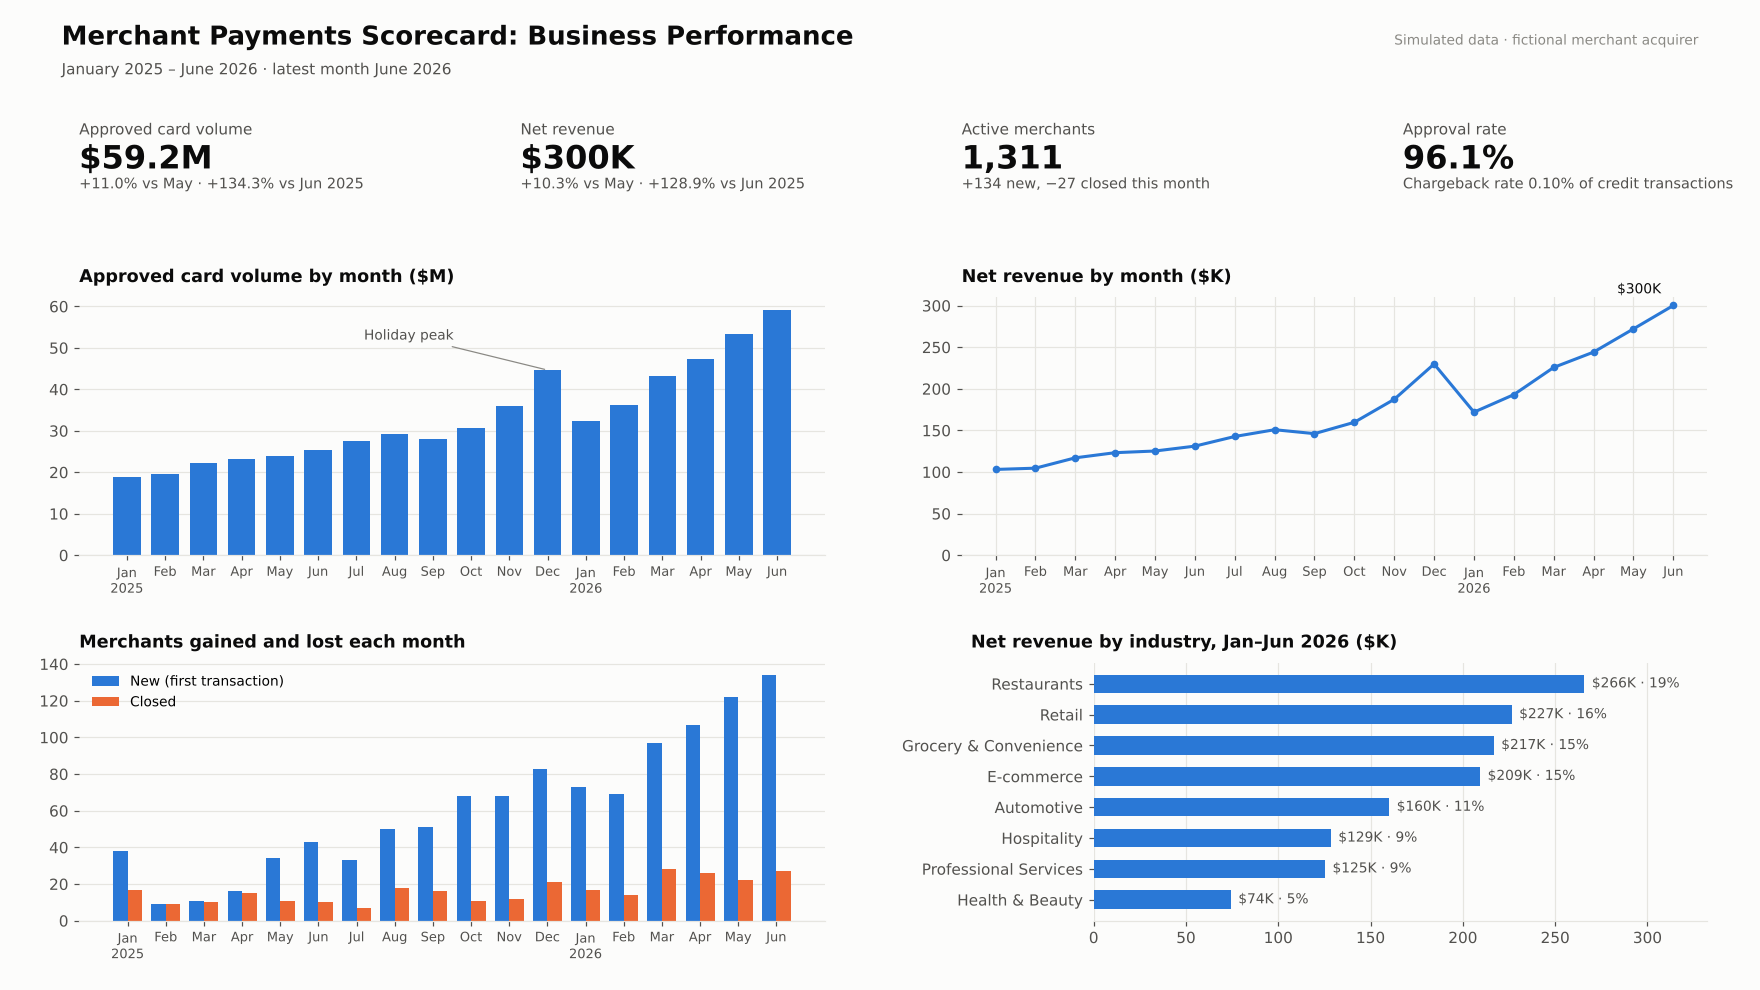

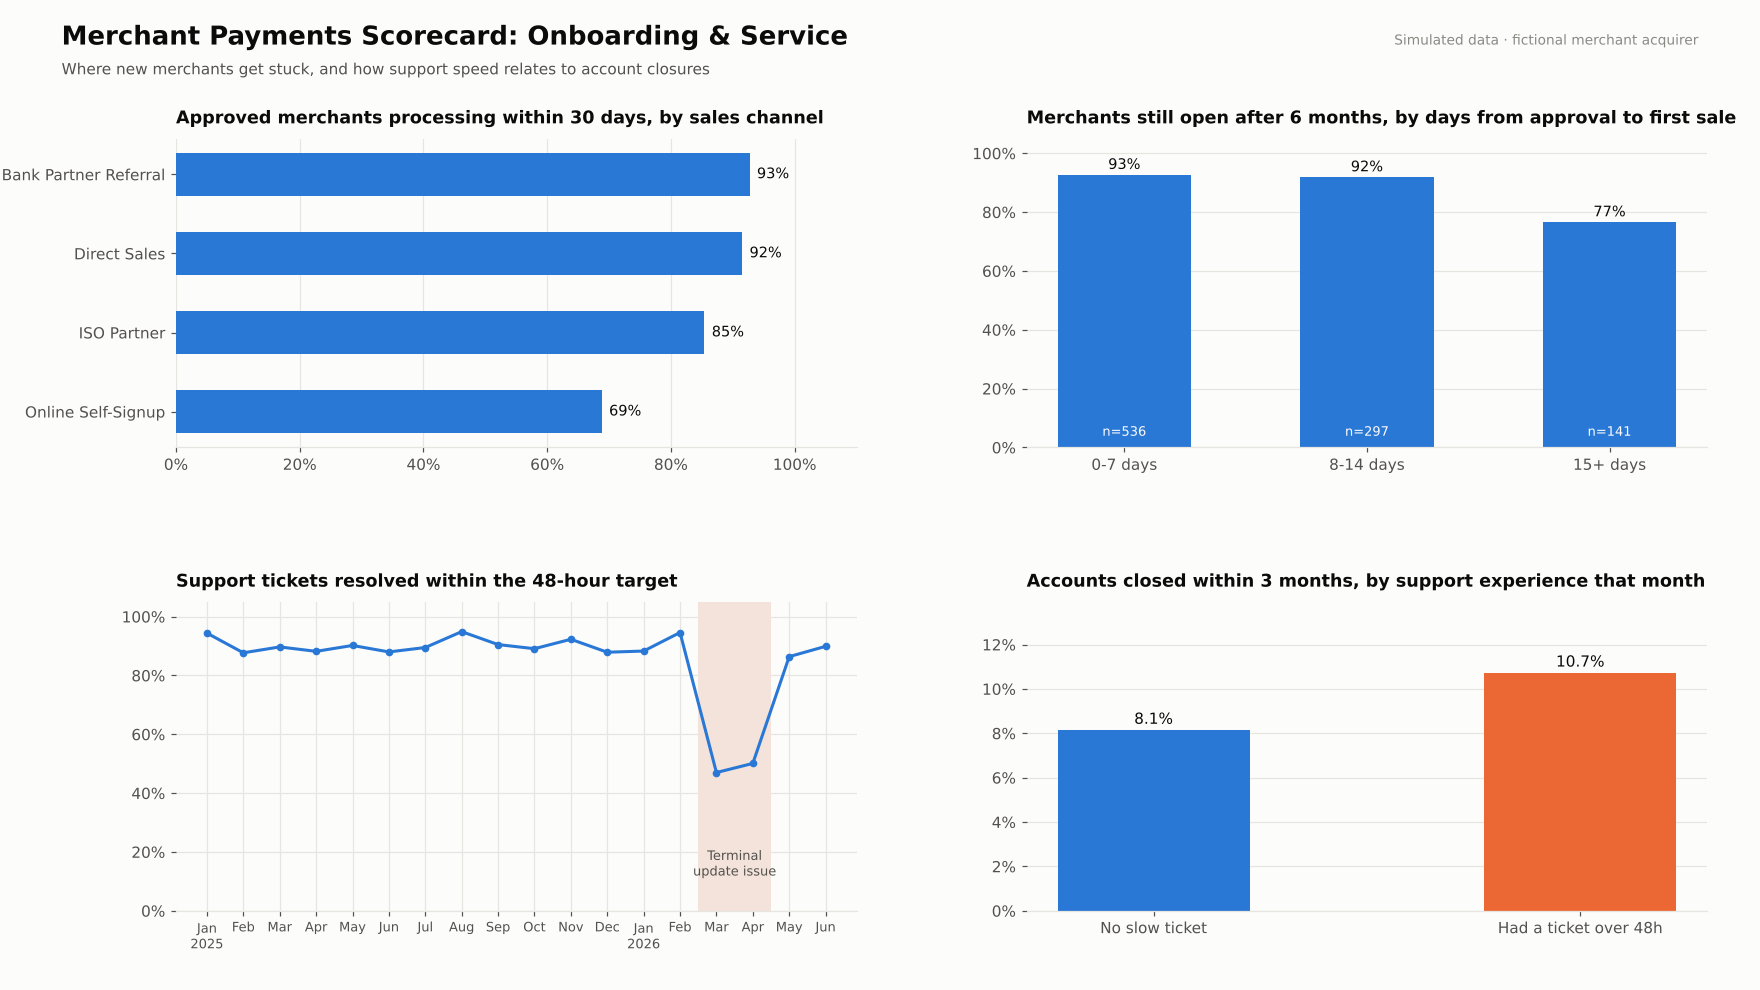

In [8]:
from IPython.display import Image, display
display(Image("../dashboard/page1_business_performance.png"))
display(Image("../dashboard/page2_onboarding_and_service.png"))